# Import Kaggle Dataset

In [1]:
import pandas as pd
import os
import kagglehub # May need to install this package if not already installed (pip install kagglehub)

path = kagglehub.dataset_download("dillonmyrick/bells-palsy-clinical-trial")
files = os.listdir(path) # Lists files

csv_file = [f for f in files if f.endswith('.csv')][0] # Find the first file that ends in .csv
csv_path = os.path.join(path, csv_file) # Join path and CSV file

df = pd.read_csv(csv_path)

# 1. Data Cleaning

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

#df = pd.read_csv("/Users/kimmeebusby/Desktop/ML/ML Project/Bells Palsy Clinical Trial.csv")

#Changing Sex to dummy variables, Male = 1, Female = 0
df["Sex"]= (df["Sex"] == "Male").astype(int)

#Changing Within 24 hr to 0, >24 to ≤48 hr to 1, >48 to ≤72 hr to 2, REMOVED the Unknown
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].map({"Within 24 hr": 0, ">24 to ≤48 hr": 1, ">48 to ≤72 hr": 2})


#Changing Received Prednisolone to No = 0, Yes = 1 and Received Acyclovir to No = 0, Yes = 1
df["Received Prednisolone"] = df["Received Prednisolone"].map({"Yes": 1, "No": 0})
df["Received Acyclovir"] = df["Received Acyclovir"].map({"Yes": 1, "No": 0})

#Changing Full Recovery in 3 months to No = 0, Yes = 1 and Full Recovery in 9 months to No = 0, Yes = 1
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].map({"No": 0, "Yes": 1})
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].map({"No": 0, "Yes": 1})

#Dropping Treatment Group since its the same as received prednislone/acyclovir
df= df.drop("Treatment Group", axis = 1)

#Convert to floats
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].astype("Int64") # supports missing values
df["Received Prednisolone"] = df["Received Prednisolone"].astype(int)
df["Received Acyclovir"] = df["Received Acyclovir"].astype(int)
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].astype(int)
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].astype(int)

#Drop NA Rows
df = df.dropna()

# Features and Target Variables
x = df[["Sex", "Age", "Baseline Score on House–Brackmann scale", "Time between onset of symptoms and start of treatment", "Received Prednisolone", "Received Acyclovir"]]

y_3month_score = df["3-Month Score on House–Brackmann scale"]
y_3month_recovery = df["Full Recovery in 3 Months"]
y_9month_score = df["9-Month Score on House–Brackmann scale"]
y_9month_recovery = df["Full Recovery in 9 Months"]

#Standardize the Features
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

def clean_stats(x): # Helper function to clean output
    return round(float(x), 4)

# 2. Dataset Split

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate, LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, make_scorer
from sklearn.exceptions import UndefinedMetricWarning
import warnings
import numpy as np

x = df[["Sex", "Age", "Baseline Score on House–Brackmann scale", "Time between onset of symptoms and start of treatment", "Received Prednisolone", "Received Acyclovir"]]

scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='weighted', zero_division=0),
    'recall': make_scorer(recall_score, average='weighted', zero_division=0),
    'f1': make_scorer(f1_score, average='weighted', zero_division=0)
}

def run_stratified_kfold(x, y, target_name, n_splits=3):

    pipeline = Pipeline([ # Standardize + Logistic Regression with balanced class weights
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ])

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42) #

    with warnings.catch_warnings(): # Ignore warnings about undefined metrics when a class is missing in a fold
        warnings.simplefilter("ignore", UndefinedMetricWarning)
        scores = cross_validate(pipeline, x, y, cv=skf, scoring=scoring)

    results = {
        "Accuracy": [clean_stats(np.mean(scores['test_accuracy'])), clean_stats(np.std(scores['test_accuracy']))],
        "Precision": [clean_stats(np.mean(scores['test_precision'])), clean_stats(np.std(scores['test_precision']))],
        "Recall": [clean_stats(np.mean(scores['test_recall'])), clean_stats(np.std(scores['test_recall']))],
        "F1 Score": [clean_stats(np.mean(scores['test_f1'])), clean_stats(np.std(scores['test_f1']))]
    }

    print(f"==================== {target_name} ====================")
    for metric, (mean, std) in results.items():
        print(f"  {metric:<12} Mean: {mean:.3f}  Std: {std:.3f}")
    print()

    return results

def run_loo(x, y, target_name):

    pipeline = Pipeline([ # Standardize + Logistic Regression with balanced class weights
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ])

    loo = LeaveOneOut()

    with warnings.catch_warnings(): # Ignore warnings about undefined metrics when a class is missing in a fold
        warnings.simplefilter("ignore", UndefinedMetricWarning)
        scores = cross_validate(pipeline, x, y, cv=loo, scoring=scoring)

    results = {
        "Accuracy": [clean_stats(np.mean(scores['test_accuracy'])), clean_stats(np.std(scores['test_accuracy']))],
        "Precision": [clean_stats(np.mean(scores['test_precision'])), clean_stats(np.std(scores['test_precision']))],
        "Recall": [clean_stats(np.mean(scores['test_recall'])), clean_stats(np.std(scores['test_recall']))],
        "F1 Score": [clean_stats(np.mean(scores['test_f1'])), clean_stats(np.std(scores['test_f1']))]
    }

    print(f"==================== {target_name} ====================")
    for metric, (mean, std) in results.items():
        print(f"  {metric:<12} Mean: {mean:.3f}  Std: {std:.3f}")
    print()

    return results

def compare_splits(skf_results, loo_results, target_name):
    print(f"==================== {target_name} Comparison ====================")
    print(f"  {'Metric':<12} {'SKF Mean':>10} {'LOO Mean':>10} {'Difference':>12}")
    print(f"  {'-'*46}")
    for metric in skf_results:
        skf_mean = skf_results[metric][0]
        loo_mean = loo_results[metric][0]
        diff = round(loo_mean - skf_mean, 4)
        direction = "↑" if diff > 0 else "↓" if diff < 0 else "="
        print(f"  {metric:<12} {skf_mean:>10.3f} {loo_mean:>10.3f} {diff:>+10.3f} {direction}")
    print()

# Run Stratified K-Fold
print("==================== Stratified K-Fold Results ====================")
skf_3month_score = run_stratified_kfold(x, df["3-Month Score on House–Brackmann scale"], "3-Month HB Score")
skf_3month_recovery = run_stratified_kfold(x, df["Full Recovery in 3 Months"], "3-Month Recovery")
skf_9month_score = run_stratified_kfold(x, df["9-Month Score on House–Brackmann scale"], "9-Month HB Score")
skf_9month_recovery = run_stratified_kfold(x, df["Full Recovery in 9 Months"], "9-Month Recovery")

# Run LOO
print("==================== Leave-One-Out Results ====================")
loo_3month_score = run_loo(x, df["3-Month Score on House–Brackmann scale"], "3-Month HB Score")
loo_3month_recovery = run_loo(x, df["Full Recovery in 3 Months"],"3-Month Recovery")
loo_9month_score = run_loo(x, df["9-Month Score on House–Brackmann scale"], "9-Month HB Score")
loo_9month_recovery = run_loo(x, df["Full Recovery in 9 Months"], "9-Month Recovery")

# Compare results
print("==================== Comparison Results ====================")
compare_splits(skf_3month_score, loo_3month_score, "3-Month HB Score")
compare_splits(skf_3month_recovery, loo_3month_recovery, "3-Month Recovery")
compare_splits(skf_9month_score, loo_9month_score, "9-Month HB Score")
compare_splits(skf_9month_recovery, loo_9month_recovery, "9-Month Recovery")

==================== Stratified K-Fold Results ====================
==================== 3-Month HB Score ====================
  Accuracy     Mean: 0.507  Std: 0.027
  Precision    Mean: 0.663  Std: 0.035
  Recall       Mean: 0.507  Std: 0.027
  F1 Score     Mean: 0.570  Std: 0.030

==================== 3-Month Recovery ====================
  Accuracy     Mean: 0.657  Std: 0.037
  Precision    Mean: 0.712  Std: 0.017
  Recall       Mean: 0.657  Std: 0.037
  F1 Score     Mean: 0.672  Std: 0.032

==================== 9-Month HB Score ====================
  Accuracy     Mean: 0.564  Std: 0.087
  Precision    Mean: 0.836  Std: 0.004
  Recall       Mean: 0.564  Std: 0.087
  F1 Score     Mean: 0.661  Std: 0.063

==================== 9-Month Recovery ====================
  Accuracy     Mean: 0.675  Std: 0.067
  Precision    Mean: 0.859  Std: 0.012
  Recall       Mean: 0.675  Std: 0.067
  F1 Score     Mean: 0.735  Std: 0.050

==================== Leave-One-Out Results ====================
====

# 3. Feature Selection

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif


def evaluate_model(model, x_train, x_test, y_train, y_test):
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    return accuracy, precision, recall, f1

def bin_hb_score(score): # Bins the HB score into 3 categories for number of folds
    if score <= 2:
        return 0 # 1-2 Good (0)
    elif score <= 4:
        return 1 # 3-4 Moderate (1)
    else:
        return 2 # 5-6 Severe (2)

df['3-Month Score Binned'] = df['3-Month Score on House–Brackmann scale'].apply(bin_hb_score)
df['9-Month Score Binned'] = df['9-Month Score on House–Brackmann scale'].apply(bin_hb_score)

# Updated y variables
y_3month_binned = df['3-Month Score Binned']
y_9month_binned = df['9-Month Score Binned']

def run_kfold_analysis(x, y, target_name, n_features=3, n_splits=3):
    feature_names = x.columns # Identifies feature names for later tallying
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42) # Uses stratified k-fold for data split

    # Initialize storage for all 6 methods
    methods = ["All-in", "Forward", "Backward", "Bidirectional", "ANOVA", "Mutual Info"]
    method_metrics = {m: [] for m in methods} # Stores metrics for each method across folds
    feature_tally = {m: [] for m in methods if m != "All-in"} # Stores selected features for methods

    print(f"==================== {target_name} (K-Fold Mode) ====================\n")

    for fold, (train_idx, test_idx) in enumerate(skf.split(x, y), 1): # Iterates through each fold
        x_train_raw, x_test_raw = x.iloc[train_idx], x.iloc[test_idx] # Splits data into train/test for this fold
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx] # Splits target variable into train/test for this fold

        scaler = StandardScaler()
        x_train = scaler.fit_transform(x_train_raw) # Standardizes features based on training data
        x_test = scaler.transform(x_test_raw) # Standardizes test data using training data parameters

        model = LogisticRegression(max_iter=1000, class_weight='balanced') # Logistic Regression with balanced class weights to handle any class imbalance

        # 1. All-In
        method_metrics["All-in"].append(evaluate_model(model, x_train, x_test, y_train, y_test)) # Evaluates model using all features and stores metrics

        # 2. Forward
        sfs_f = SFS(model, k_features=n_features, forward=True, floating=False, cv=3) # Forward Selection with specified number of features and 3-fold CV
        sfs_f.fit(x_train, y_train) # Fits the forward selection model to the training data
        method_metrics["Forward"].append(evaluate_model(model, sfs_f.transform(x_train), sfs_f.transform(x_test), y_train, y_test))
        feature_tally["Forward"].extend([feature_names[int(i)] for i in sfs_f.k_feature_names_]) # Tally selected features for forward selection

        # 3. Backward
        sfs_b = SFS(model, k_features=n_features, forward=False, floating=False, cv=3) # Backward Selection with specified number of features and 3-fold CV
        sfs_b.fit(x_train, y_train) # Fits the backward selection model to the training data
        method_metrics["Backward"].append(evaluate_model(model, sfs_b.transform(x_train), sfs_b.transform(x_test), y_train, y_test)) # Evaluates model using features selected by backward selection and stores metrics
        feature_tally["Backward"].extend([feature_names[int(i)] for i in sfs_b.k_feature_names_]) # Tally selected features for backward selection

        # 4. Bidirectional (Floating=True)
        sfs_bi = SFS(model, k_features=n_features, forward=True, floating=True, cv=3) # Bidirectional Selection with specified number of features, forward direction, and floating enabled for more flexible selection
        sfs_bi.fit(x_train, y_train) # Fits the bidirectional selection model to the training data
        method_metrics["Bidirectional"].append(evaluate_model(model, sfs_bi.transform(x_train), sfs_bi.transform(x_test), y_train, y_test)) # Evaluates model using features selected by bidirectional selection and stores metrics
        feature_tally["Bidirectional"].extend([feature_names[int(i)] for i in sfs_bi.k_feature_names_]) # Tally selected features for bidirectional selection

        # 5. ANOVA
        anova = SelectKBest(score_func=f_classif, k=n_features) # ANOVA feature selection with specified number of features
        anova.fit(x_train, y_train) # Fits the ANOVA feature selection model to the training data
        method_metrics["ANOVA"].append(evaluate_model(model, anova.transform(x_train), anova.transform(x_test), y_train, y_test)) # Evaluates model using features selected by ANOVA and stores metrics
        feature_tally["ANOVA"].extend(list(feature_names[anova.get_support()])) # Tally selected features for ANOVA selection

        # 6. Mutual Info
        mi = SelectKBest(score_func=mutual_info_classif, k=n_features) # Mutual Information feature selection with specified number of features
        mi.fit(x_train, y_train) # Fits the Mutual Information feature selection model to the training data
        method_metrics["Mutual Info"].append(evaluate_model(model, mi.transform(x_train), mi.transform(x_test), y_train, y_test)) # Evaluates model using features selected by Mutual Information and stores metrics
        feature_tally["Mutual Info"].extend(list(feature_names[mi.get_support()])) # Tally selected features for Mutual Information selection

    summary_data = []
    all_consensus_votes = [] # Master list to track EVERY feature pick across EVERY method/fold for this Y

    for method in methods:
        scores = method_metrics[method]
        if scores:
            avg_scores = np.mean(scores, axis=0)
            summary_data.append({
                "Method": method,
                "Accuracy": clean_stats(avg_scores[0]),
                "Precision": clean_stats(avg_scores[1]),
                "Recall": clean_stats(avg_scores[2]),
                "F1": clean_stats(avg_scores[3])
            })
            if method != "All-in":
                all_consensus_votes.extend(feature_tally[method]) # Add this method's selected features to the master consensus list (excluding "All-in" since it doesn't select features)

    results_df = pd.DataFrame(summary_data).sort_values(by="Accuracy", ascending=False) # Prints results table sorted by accuracy
    print(results_df.to_string(index=False))

    print(f"\n>>> TOP 3 FEATURES FOR: {target_name}")
    final_counts = pd.Series(all_consensus_votes).value_counts().head(3) # Get the top 3 most frequently selected features and their counts

    for i, (feature, votes) in enumerate(final_counts.items(), 1):
        # Calculate what percentage of total possible "votes" it got
        # (Total votes = number of selection methods * number of folds)
        total_possible = (len(methods) - 1) * n_splits
        vote_percent = int((votes / total_possible) * 100)
        print(f"  {i}. {feature:<40} (Stability Score: {vote_percent}%)")

    # Return the list of top 3 strings so you can use them in your next code block
    return final_counts.index.tolist()

In [ ]:
results_3month_recovery = run_kfold_analysis(x,y_3month_recovery,"Full Recovery in 3 Months")
results_3month_score = run_kfold_analysis(x, y_3month_score, "3-Month HB Score")
results_3month_binned = run_kfold_analysis(x, y_3month_binned, "3-Month HB Score (Binned)")


results_9month_recovery = run_kfold_analysis(x,y_9month_recovery,"Full Recovery in 9 Months")
results_9month_score = run_kfold_analysis(x, y_9month_score, "9-Month HB Score")
results_9month_binned = run_kfold_analysis(x, y_9month_binned, "9-Month HB Score (Binned)")

==================== Full Recovery in 3 Months (K-Fold Mode) ====================

       Method  Accuracy  Precision  Recall     F1
        ANOVA    0.6734     0.7341  0.6734 0.6880
  Mutual Info    0.6734     0.7092  0.6734 0.6855
     Backward    0.6652     0.7226  0.6652 0.6811
      Forward    0.6612     0.7133  0.6612 0.6765
Bidirectional    0.6612     0.7133  0.6612 0.6765
       All-in    0.6571     0.7124  0.6571 0.6723

>>> TOP 3 FEATURES FOR: Full Recovery in 3 Months
  1. Age                                      (Stability Score: 100%)
  2. Baseline Score on House–Brackmann scale  (Stability Score: 86%)
  3. Sex                                      (Stability Score: 46%)
==================== 3-Month HB Score (K-Fold Mode) ====================



/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklea

       Method  Accuracy  Precision  Recall     F1
        ANOVA    0.5354     0.6854  0.5354 0.5912
     Backward    0.5314     0.6812  0.5314 0.5922
Bidirectional    0.5192     0.6767  0.5192 0.5828
      Forward    0.5192     0.6767  0.5192 0.5828
       All-in    0.5070     0.6635  0.5070 0.5697
  Mutual Info    0.4991     0.6747  0.4991 0.5657

>>> TOP 3 FEATURES FOR: 3-Month HB Score
  1. Age                                      (Stability Score: 100%)
  2. Baseline Score on House–Brackmann scale  (Stability Score: 86%)
  3. Received Prednisolone                    (Stability Score: 40%)
==================== 3-Month HB Score (Binned) (K-Fold Mode) ====================

       Method  Accuracy  Precision  Recall     F1
        ANOVA    0.6815     0.9240  0.6815 0.7667
       All-in    0.6733     0.9118  0.6733 0.7601
     Backward    0.6551     0.8981  0.6551 0.7476
      Forward    0.6510     0.8977  0.6510 0.7445
Bidirectional    0.6510     0.8977  0.6510 0.7445
  Mutual Info    

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklea

       Method  Accuracy  Precision  Recall     F1
        ANOVA    0.5779     0.8587  0.5779 0.6751
       All-in    0.5636     0.8364  0.5636 0.6613
  Mutual Info    0.5515     0.8444  0.5515 0.6514
      Forward    0.5292     0.8254  0.5292 0.6341
Bidirectional    0.5292     0.8254  0.5292 0.6341
     Backward    0.5292     0.8254  0.5292 0.6341

>>> TOP 3 FEATURES FOR: 9-Month HB Score
  1. Age                                      (Stability Score: 93%)
  2. Sex                                      (Stability Score: 80%)
  3. Baseline Score on House–Brackmann scale  (Stability Score: 46%)
==================== 9-Month HB Score (Binned) (K-Fold Mode) ====================

       Method  Accuracy  Precision  Recall     F1
       All-in    0.7465     0.9548  0.7465 0.8310
        ANOVA    0.7303     0.9544  0.7303 0.8200
      Forward    0.7201     0.9536  0.7201 0.8127
Bidirectional    0.7201     0.9536  0.7201 0.8127
  Mutual Info    0.7160     0.9540  0.7160 0.8090
     Backward    0

### Feature Selection Visuals

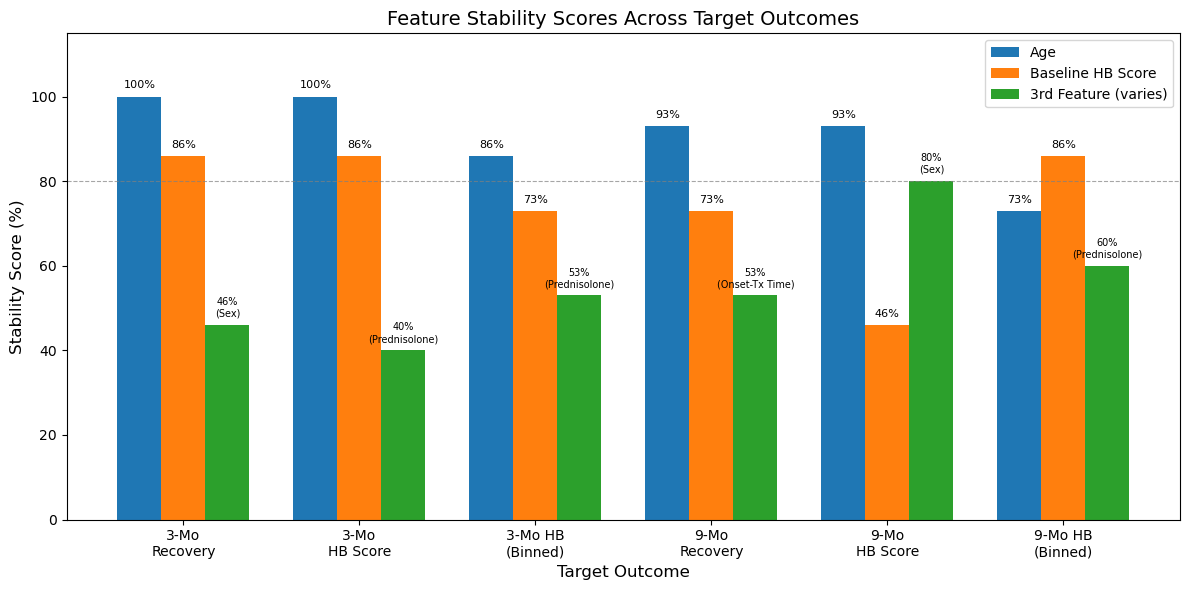

In [3]:
import matplotlib.pyplot as plt
import numpy as np 

targets = ['3-Mo\nRecovery', '3-Mo\nHB Score', '3-Mo HB\n(Binned)', 
           '9-Mo\nRecovery', '9-Mo\nHB Score', '9-Mo HB\n(Binned)']

age =           [100, 100, 86, 93, 93, 73]
baseline_hb =   [86,  86,  73, 73, 46, 86]
third_feature = [46,  40,  53, 53, 80, 60]
third_labels =  ['Sex', 'Prednisolone', 'Prednisolone', 
                 'Onset-Tx Time', 'Sex', 'Prednisolone']

x = np.arange(len(targets))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(x - width, age, width, label='Age')
bars2 = ax.bar(x, baseline_hb, width, label='Baseline HB Score')
bars3 = ax.bar(x + width, third_feature, width, label='3rd Feature (varies)')

ax.set_xlabel('Target Outcome', fontsize=12)
ax.set_ylabel('Stability Score (%)', fontsize=12)
ax.set_title('Feature Stability Scores Across Target Outcomes', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(targets, fontsize=10)
ax.set_ylim(0, 115)
ax.legend(fontsize=10)
ax.axhline(y=80, color='gray', linestyle='--', linewidth=0.8, alpha=0.7, label='80% threshold')

# Add value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f'{int(bar.get_height())}%', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f'{int(bar.get_height())}%', ha='center', va='bottom', fontsize=8)
for i, bar in enumerate(bars3):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f'{int(bar.get_height())}%\n({third_labels[i]})', ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.show()

# 4. Model Selection

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

def run_model_selection(x, y, target_name, n_splits=3):

    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
        "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
        "SVM": SVC(class_weight='balanced', random_state=42)
    }
    print(f"==================== {target_name} ====================")

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    scoring = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']
    results = {}

    for model_name, model in models.items():
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', model)
        ])

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", UndefinedMetricWarning)
            scores = cross_validate(pipeline, x, y, cv=skf, scoring=scoring)

        results[model_name] = {
            "Accuracy": [clean_stats(np.mean(scores['test_accuracy'])), clean_stats(np.std(scores['test_accuracy']))],
            "Precision": [clean_stats(np.mean(scores['test_precision_weighted'])), clean_stats(np.std(scores['test_precision_weighted']))],
            "Recall": [clean_stats(np.mean(scores['test_recall_weighted'])), clean_stats(np.std(scores['test_recall_weighted']))],
            "F1 Score": [clean_stats(np.mean(scores['test_f1_weighted'])), clean_stats(np.std(scores['test_f1_weighted']))]
        }

        print(f"\n  {model_name}")
        for metric, (mean, std) in results[model_name].items():
            print(f"{metric:<12} Mean: {mean:.3f}  Std: {std:.3f}")

    # Print best model summary
    best_model = max(results, key=lambda m: results[m]["F1 Score"][0])
    best_f1 = results[best_model]["F1 Score"][0]
    best_acc = results[best_model]["Accuracy"][0]
    print(f"\n  Best Model: {best_model}  (Accuracy: {best_acc:.3f}, F1: {best_f1:.3f})")
    print()

    return results

In [ ]:
top_3month_recovery_features = x[['Age', 'Baseline Score on House–Brackmann scale', 'Sex']]
top_3month_score_features = x[['Age', 'Baseline Score on House–Brackmann scale', 'Received Prednisolone']]
top_3month_binned_features = x[['Age', 'Baseline Score on House–Brackmann scale', 'Received Prednisolone']]
top_9month_recovery_features = x[['Age','Baseline Score on House–Brackmann scale', 'Time between onset of symptoms and start of treatment']]
top_9month_score_features = x[['Age','Sex', 'Baseline Score on House–Brackmann scale']]
top_9month_binned_features = x[['Baseline Score on House–Brackmann scale', 'Age', 'Received Prednisolone']]

ms_3month_recovery = run_model_selection(top_3month_recovery_features, df["Full Recovery in 3 Months"], "Full Recovery in 3 Months (Top 3 Features)")
ms_3month_score = run_model_selection(top_3month_score_features, df["3-Month Score on House–Brackmann scale"], "3-Month HB Score (Top 3 Features)")
ms_3month_binned = run_model_selection(top_3month_binned_features, y_3month_binned, "3-Month HB Score (Binned - Top 3)")

ms_9month_recovery = run_model_selection(top_9month_recovery_features, df["Full Recovery in 9 Months"], "Full Recovery in 9 Months (Top 3 Features)")
ms_9month_score = run_model_selection(top_9month_score_features, df["9-Month Score on House–Brackmann scale"], "9-Month HB Score (Top 3 Features)")
ms_9month_binned = run_model_selection(top_9month_binned_features, y_9month_binned, "9-Month HB Score (Binned - Top 3)")

==================== Full Recovery in 3 Months (Top 3 Features) ====================

  Logistic Regression
Accuracy     Mean: 0.679  Std: 0.021
Precision    Mean: 0.734  Std: 0.030
Recall       Mean: 0.679  Std: 0.021
F1 Score     Mean: 0.694  Std: 0.021

  Random Forest
Accuracy     Mean: 0.643  Std: 0.013
Precision    Mean: 0.643  Std: 0.020
Recall       Mean: 0.643  Std: 0.013
F1 Score     Mean: 0.642  Std: 0.016

  SVM
Accuracy     Mean: 0.651  Std: 0.021
Precision    Mean: 0.729  Std: 0.028
Recall       Mean: 0.651  Std: 0.021
F1 Score     Mean: 0.669  Std: 0.019

  Best Model: Logistic Regression  (Accuracy: 0.679, F1: 0.694)

==================== 3-Month HB Score (Top 3 Features) ====================

  Logistic Regression
Accuracy     Mean: 0.535  Std: 0.026
Precision    Mean: 0.685  Std: 0.021
Recall       Mean: 0.535  Std: 0.026
F1 Score     Mean: 0.591  Std: 0.019

  Random Forest
Accuracy     Mean: 0.615  Std: 0.039
Precision    Mean: 0.618  Std: 0.012
Recall       Mean: 0

### Model Selection Visualization

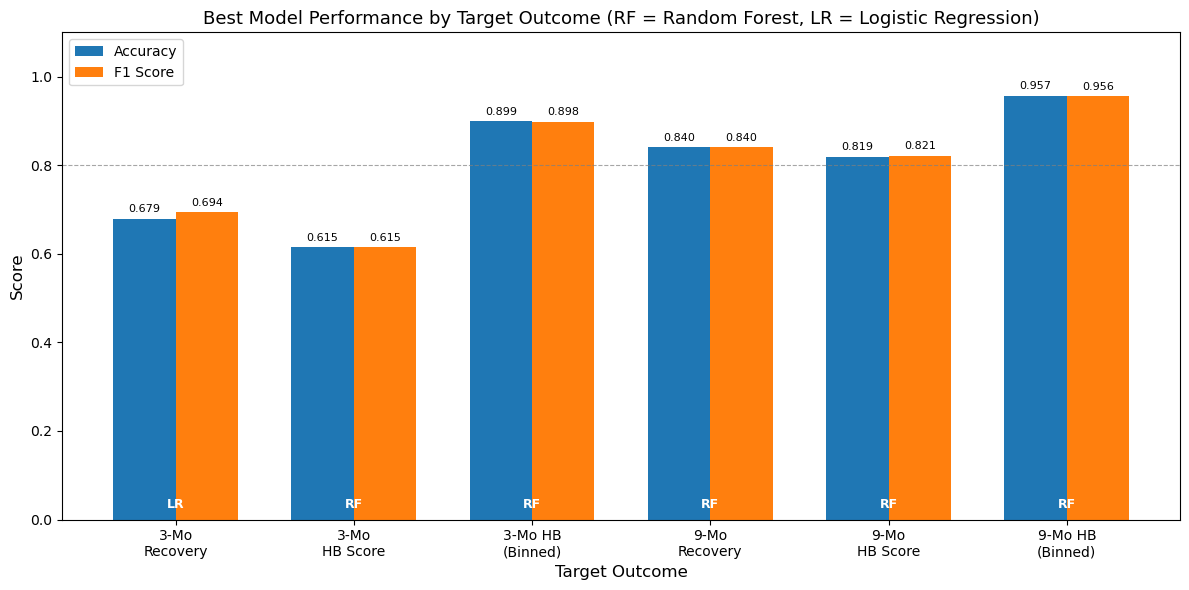

In [9]:
import matplotlib.pyplot as plt
import numpy as np

targets = ['3-Mo\nRecovery', '3-Mo\nHB Score', '3-Mo HB\n(Binned)',
           '9-Mo\nRecovery', '9-Mo\nHB Score', '9-Mo HB\n(Binned)']

best_models = ['LR', 'RF', 'RF', 'RF', 'RF', 'RF']

accuracy = [0.679, 0.615, 0.899, 0.840, 0.819, 0.957]
f1 =       [0.694, 0.615, 0.898, 0.840, 0.821, 0.956]

x = np.arange(len(targets))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(x - width/2, accuracy, width, label='Accuracy')
bars2 = ax.bar(x + width/2, f1, width, label='F1 Score')

# Color bars differently for LR vs RF
for i, model in enumerate(best_models):
    if model == 'LR':
        bars1[i]
        bars2[i]

ax.set_xlabel('Target Outcome', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Best Model Performance by Target Outcome (RF = Random Forest, LR = Logistic Regression)', 
             fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(targets, fontsize=10)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=10)
ax.axhline(y=0.8, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)

# Add value labels
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

# Annotate best model
for i, model in enumerate(best_models):
    ax.text(x[i], 0.02, model, ha='center', va='bottom', 
            fontsize=9, fontweight='bold', color='white')

plt.tight_layout()
plt.show()

## Hyperparameter Tuning

In [ ]:
import pip
from sklearn.model_selection import GridSearchCV

def tune_random_forest(x, y):
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5, 10]
    }

    rf = RandomForestClassifier(class_weight='balanced', random_state=42)
    grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='accuracy')
    grid_search.fit(x, y)

    print(f"Best Parameters for {y.name}: {grid_search.best_params_}")
    return grid_search.best_estimator_

def rerun_random_forest(x, y, target_name, params):
    final_rf = RandomForestClassifier(**params, class_weight='balanced', random_state=42)

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', final_rf)
    ])

    scoring = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']
    scores = cross_validate(pipeline, x, y, cv=skf, scoring=scoring)

    print(f"==================== FINAL OPTIMIZED: {target_name} ====================")
    print(f"Accuracy:  {np.mean(scores['test_accuracy']):.3f}")
    print(f"Precision: {np.mean(scores['test_precision_weighted']):.3f}")
    print(f"Recall:    {np.mean(scores['test_recall_weighted']):.3f}")
    print(f"F1 Score:  {np.mean(scores['test_f1_weighted']):.3f}\n")

    return final_rf.fit(x, y) # Returns fitted model for feature importance

In [ ]:
best_rf_model_3recovery = tune_random_forest(top_3month_recovery_features, y_3month_recovery)
best_rf_score_3month = tune_random_forest(top_3month_score_features, y_3month_score)
best_rf_model_3score_binned = tune_random_forest(top_3month_binned_features, y_3month_binned)

best_rf_model_9recovery = tune_random_forest(top_9month_recovery_features, y_9month_recovery)
best_rf_model_9score = tune_random_forest(top_9month_score_features, y_9month_score)
best_rf_model_9score_binned = tune_random_forest(top_9month_binned_features, y_9month_binned)

Best Parameters for Full Recovery in 3 Months: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 200}
Best Parameters for 3-Month Score on House–Brackmann scale: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Best Parameters for 3-Month Score Binned: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best Parameters for Full Recovery in 9 Months: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 50}
Best Parameters for 9-Month Score on House–Brackmann scale: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best Parameters for 9-Month Score Binned: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}


In [ ]:
final_rf_3recovery = rerun_random_forest(top_3month_recovery_features, y_3month_recovery, "3-Month Recovery", {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 200})
final_rf_3score = rerun_random_forest(top_3month_score_features, y_3month_score, "3-Month HB Score", {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100})
final_rf_3score_binned = rerun_random_forest(top_3month_binned_features, y_3month_binned, "3-Month HB Score (Binned)", {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100})

final_rf_9recovery = rerun_random_forest(top_9month_recovery_features, y_9month_recovery, "9-Month Recovery", {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 50})
final_rf_9score = rerun_random_forest(top_9month_score_features, y_9month_score, "9-Month HB Score", {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100})
final_rf_9score_binned = rerun_random_forest(top_9month_binned_features, y_9month_binned, "9-Month HB Score (Binned)", {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50})

==================== FINAL OPTIMIZED: 3-Month Recovery ====================
Accuracy:  0.679
Precision: 0.691
Recall:    0.679
F1 Score:  0.685



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


==================== FINAL OPTIMIZED: 3-Month HB Score ====================
Accuracy:  0.617
Precision: 0.620
Recall:    0.617
F1 Score:  0.616

==================== FINAL OPTIMIZED: 3-Month HB Score (Binned) ====================
Accuracy:  0.899
Precision: 0.898
Recall:    0.899
F1 Score:  0.898

==================== FINAL OPTIMIZED: 9-Month Recovery ====================
Accuracy:  0.838
Precision: 0.838
Recall:    0.838
F1 Score:  0.838



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


==================== FINAL OPTIMIZED: 9-Month HB Score ====================
Accuracy:  0.819
Precision: 0.822
Recall:    0.819
F1 Score:  0.821

==================== FINAL OPTIMIZED: 9-Month HB Score (Binned) ====================
Accuracy:  0.957
Precision: 0.955
Recall:    0.957
F1 Score:  0.956



### Tuning Visualization

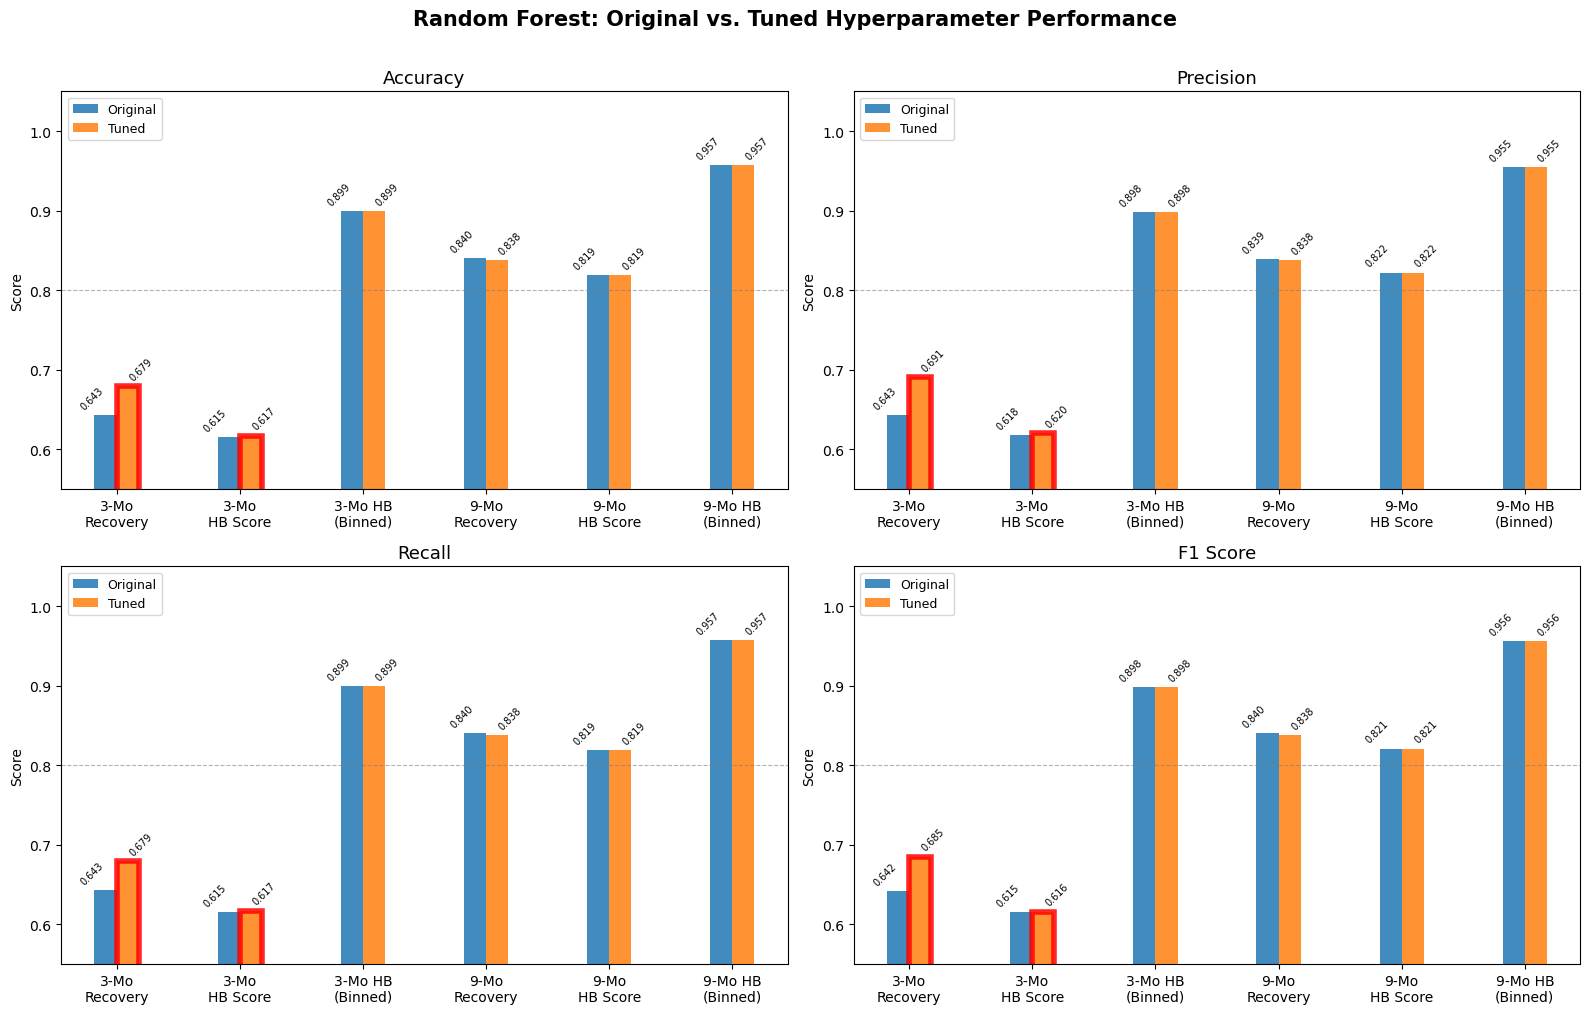

In [17]:
import matplotlib.pyplot as plt
import numpy as np

targets = ['3-Mo\nRecovery', '3-Mo\nHB Score', '3-Mo HB\n(Binned)',
           '9-Mo\nRecovery', '9-Mo\nHB Score', '9-Mo HB\n(Binned)']

# F1 scores for original vs tuned (most representative single metric)
f1_original = [0.642, 0.615, 0.898, 0.840, 0.821, 0.956]
f1_tuned =    [0.685, 0.616, 0.898, 0.838, 0.821, 0.956]

accuracy_original = [0.643, 0.615, 0.899, 0.840, 0.819, 0.957]
accuracy_tuned =    [0.679, 0.617, 0.899, 0.838, 0.819, 0.957]

precision_original = [0.643, 0.618, 0.898, 0.839, 0.822, 0.955]
precision_tuned =    [0.691, 0.620, 0.898, 0.838, 0.822, 0.955]

recall_original = [0.643, 0.615, 0.899, 0.840, 0.819, 0.957]
recall_tuned =    [0.679, 0.617, 0.899, 0.838, 0.819, 0.957]

x = np.arange(len(targets))
width = 0.18

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=False)
fig.suptitle('Random Forest: Original vs. Tuned Hyperparameter Performance', 
             fontsize=15, fontweight='bold', y=1.01)

datasets = [
    (axes[0,0], accuracy_original, accuracy_tuned, 'Accuracy'),
    (axes[0,1], precision_original, precision_tuned, 'Precision'),
    (axes[1,0], recall_original, recall_tuned, 'Recall'),
    (axes[1,1], f1_original, f1_tuned, 'F1 Score'),
]

for ax, original, tuned, metric in datasets:
    bars1 = ax.bar(x - width/2, original, width, label='Original', alpha=0.85)
    bars2 = ax.bar(x + width/2, tuned, width, label='Tuned', alpha=0.85)

    ax.set_title(metric, fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(targets, fontsize=10)
    ax.set_ylim(0.55, 1.05)
    ax.axhline(y=0.8, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.legend(fontsize=9)
    ax.set_ylabel('Score', fontsize=10)

    # Value labels
    for bar in bars1:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='right', va='bottom', 
                fontsize=7, rotation=45)
    for bar in bars2:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='left', va='bottom', 
                fontsize=7, rotation=45)

    # Highlight bars where tuning improved the result
    for i, (orig, tun) in enumerate(zip(original, tuned)):
        if tun > orig:
            bars2[i].set_edgecolor('red')
            bars2[i].set_linewidth(4)

plt.tight_layout()
plt.show()